In [1]:
# Standard library modules needed for setup
import os, sys, subprocess, importlib.util
# Install a package only if Python cannot find it
def ensure_package(module_name, pip_name=None):
    # Look for the module first
    if importlib.util.find_spec(module_name) is None:
        # Quiet install; check=False keeps the notebook running even if pip only warns
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module_name], check=False)
# Transformers runs the explanation generator and the reader LM
ensure_package("transformers")
# Accelerate helps place the models on the GPU
ensure_package("accelerate")
# scikit-learn gives sparse logistic experts and evaluation tools
ensure_package("sklearn", "scikit-learn")
# SciPy gives the Hungarian matching of experts to user types
ensure_package("scipy")
# Confirmation
print("Packages are ready.")

Packages are ready.


In [2]:
# General utilities
import re, gc, json, math, time, random, warnings
# Arrays
import numpy as np
# Tables
import pandas as pd
# Figures
import matplotlib.pyplot as plt
# Model backend
import torch
# Version check of Transformers
import transformers
# Tokenizer and causal LM classes
from transformers import AutoTokenizer, AutoModelForCausalLM
# Sparse (L1) and plain logistic regression
from sklearn.linear_model import LogisticRegression
# Agreement between learned and true user groups
from sklearn.metrics import adjusted_rand_score
# Optimal one-to-one matching of experts to user types
from scipy.optimize import linear_sum_assignment
# Keep the output readable
warnings.filterwarnings("ignore")
# Global seed
SEED = 11
# Seed Python
random.seed(SEED)
# Seed NumPy
np.random.seed(SEED)
# Seed PyTorch
torch.manual_seed(SEED)
# GPU if available
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# Half precision on GPU, full precision on CPU
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
# Show the device
print("Device:", DEVICE)

Device: cuda


In [3]:
# Instruction-tuned code model that writes the explanations
GEN_LM = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
# Small base model used to measure how predictable (easy to read) an explanation is
READER_LM = "Qwen/Qwen2.5-Coder-0.5B"
# Maximum length of each explanation
MAX_NEW_TOKENS = 160
# Number of simulated developers used to train the reward model
N_TRAIN_USERS = 120
# Number of new developers used for few-shot evaluation
N_TEST_USERS = 60
# Pairwise comparisons answered by each developer
N_COMPARISONS = 40
# Comparisons of a new developer kept back for evaluation
N_EVAL_COMPARISONS = 16
# Few-shot budgets (number of comparisons seen from a new developer)
K_SHOTS = [1, 2, 4, 8, 16]
# Candidate numbers of experts in the mixture
N_EXPERTS_GRID = [1, 2, 3, 4, 5]
# EM iterations
EM_ITERS = 30
# Inverse L1 strength of each expert (smaller = sparser)
L1_C = 0.5
# Bootstrap repetitions
N_BOOT = 1000
# Working and output folders
WORK_DIR = os.path.abspath("preference_work")
OUT_DIR = os.path.join(WORK_DIR, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)
# Confirm
print("Outputs will be saved in:", OUT_DIR)

Outputs will be saved in: /content/preference_work/outputs


In [4]:
# Short Python functions that developers ask the assistant to explain
SNIPPETS = {
    "is_palindrome": "def is_palindrome(s):\n    s = s.lower()\n    return s == s[::-1]",
    "running_sum": "def running_sum(nums):\n    total = 0\n    out = []\n    for n in nums:\n        total += n\n        out.append(total)\n    return out",
    "count_vowels": "def count_vowels(text):\n    return sum(1 for ch in text.lower() if ch in 'aeiou')",
    "factorial": "def factorial(n):\n    if n <= 1:\n        return 1\n    return n * factorial(n - 1)",
    "binary_search": "def binary_search(arr, target):\n    lo, hi = 0, len(arr) - 1\n    while lo <= hi:\n        mid = (lo + hi) // 2\n        if arr[mid] == target:\n            return mid\n        if arr[mid] < target:\n            lo = mid + 1\n        else:\n            hi = mid - 1\n    return -1",
    "word_freq": "def word_freq(text):\n    counts = {}\n    for w in text.split():\n        counts[w] = counts.get(w, 0) + 1\n    return counts",
    "flatten": "def flatten(rows):\n    return [x for row in rows for x in row]",
    "fib": "def fib(n):\n    a, b = 0, 1\n    for _ in range(n):\n        a, b = b, a + b\n    return a",
    "max_index": "def max_index(values):\n    best = 0\n    for i in range(1, len(values)):\n        if values[i] > values[best]:\n            best = i\n    return best",
    "dedupe": "def dedupe(items):\n    seen = set()\n    out = []\n    for x in items:\n        if x not in seen:\n            seen.add(x)\n            out.append(x)\n    return out",
    "gcd": "def gcd(a, b):\n    while b:\n        a, b = b, a % b\n    return a",
    "chunk": "def chunk(lst, size):\n    return [lst[i:i + size] for i in range(0, len(lst), size)]",
    "is_prime": "def is_prime(n):\n    if n < 2:\n        return False\n    for d in range(2, int(n ** 0.5) + 1):\n        if n % d == 0:\n            return False\n    return True",
    "reverse_words": "def reverse_words(sentence):\n    return ' '.join(reversed(sentence.split()))",
    "merge_sorted": "def merge_sorted(a, b):\n    i = j = 0\n    out = []\n    while i < len(a) and j < len(b):\n        if a[i] <= b[j]:\n            out.append(a[i]); i += 1\n        else:\n            out.append(b[j]); j += 1\n    return out + a[i:] + b[j:]",
    "transpose": "def transpose(m):\n    return [list(col) for col in zip(*m)]",
    "digit_sum": "def digit_sum(n):\n    return sum(int(d) for d in str(abs(n)))",
    "group_by_len": "def group_by_len(words):\n    groups = {}\n    for w in words:\n        groups.setdefault(len(w), []).append(w)\n    return groups",
    "clamp": "def clamp(x, low, high):\n    return max(low, min(x, high))",
    "count_if": "def count_if(items, pred):\n    n = 0\n    for x in items:\n        if pred(x):\n            n += 1\n    return n",
    "rotate": "def rotate(lst, k):\n    if not lst:\n        return lst\n    k = k % len(lst)\n    return lst[-k:] + lst[:-k]",
    "pairs_sum": "def pairs_sum(nums, target):\n    seen = set()\n    found = []\n    for n in nums:\n        if target - n in seen:\n            found.append((target - n, n))\n        seen.add(n)\n    return found",
    "capitalize_all": "def capitalize_all(words):\n    return [w[:1].upper() + w[1:] for w in words]",
    "mean_std": "def mean_std(xs):\n    m = sum(xs) / len(xs)\n    var = sum((x - m) ** 2 for x in xs) / len(xs)\n    return m, var ** 0.5",
}
# Sanity check: every snippet must be valid Python
for name, code in SNIPPETS.items():
    compile(code, name, "exec")
# Factorial instruction design: detail x example x confidence (manipulated, as in studies of how AI answers shape beliefs)
DETAIL = {"brief": "Be brief: use at most three sentences.", "detailed": "Explain in detail, step by step."}
EXAMPLE = {"no_example": "Do not include any example call.", "example": "Include one concrete example call and its result."}
CONFIDENCE = {"hedged": "Where you are not completely sure, say so with words like 'likely' or 'may'.", "assertive": "State everything with full confidence."}
# All eight variants
VARIANTS = [(d, e, c) for d in DETAIL for e in EXAMPLE for c in CONFIDENCE]
print(len(SNIPPETS), "snippets x", len(VARIANTS), "variants =", len(SNIPPETS) * len(VARIANTS), "explanations")

24 snippets x 8 variants = 192 explanations


In [5]:
# Load a model and its tokenizer
def load_lm(name):
    # Fast tokenizer
    tok = AutoTokenizer.from_pretrained(name)
    # Version 4.56+ uses dtype, older versions torch_dtype
    ver = tuple(int(x) for x in re.findall(r"\d+", transformers.__version__)[:2])
    if ver >= (4, 56):
        model = AutoModelForCausalLM.from_pretrained(name, dtype=DTYPE)
    else:
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=DTYPE)
    # Device and inference mode
    model = model.to(DEVICE)
    model.eval()
    # Padding id for generation
    if tok.pad_token_id is None:
        tok.pad_token_id = tok.eos_token_id
    return {"name": name, "tok": tok, "model": model}
# Free GPU memory
def free_lm(lm):
    lm["model"] = None
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
# Build the user request for one snippet and one variant
def build_request(code, variant):
    d, e, c = variant
    return f"Explain what this Python function does.\n```python\n{code}\n```\n{DETAIL[d]} {EXAMPLE[e]} {CONFIDENCE[c]}"
# Greedy generation with the chat template when available
def generate(lm, request):
    msgs = [{"role": "user", "content": request}]
    if getattr(lm["tok"], "chat_template", None):
        text = lm["tok"].apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    else:
        text = f"User: {request}\nAssistant:"
    enc = lm["tok"](text, return_tensors="pt", add_special_tokens=False)
    ids, mask = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
    with torch.no_grad():
        out = lm["model"].generate(input_ids=ids, attention_mask=mask, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=lm["tok"].pad_token_id)
    return lm["tok"].decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()
# Mean surprisal (bits per token) of a text under a reader LM
def mean_surprisal(lm, text, context="Explanation: "):
    enc = lm["tok"](context + text, return_tensors="pt", return_offsets_mapping=True, add_special_tokens=False)
    ids = enc["input_ids"].to(DEVICE)
    offsets = enc["offset_mapping"][0].tolist()
    with torch.no_grad():
        logits = lm["model"](input_ids=ids).logits[0].float().cpu().numpy()
    logits = logits - logits.max(axis=-1, keepdims=True)
    logp = logits - np.log(np.exp(logits).sum(axis=-1, keepdims=True))
    id_list = ids[0].cpu().numpy().tolist()
    vals = [-logp[i - 1, id_list[i]] / math.log(2) for i in range(1, len(id_list)) if offsets[i][1] > len(context)]
    return float(np.mean(vals)) if vals else 0.0
print("Helpers ready.")

Helpers ready.


In [6]:
# Generate every explanation
gen = load_lm(GEN_LM)
rows, t0 = [], time.time()
for sname, code in SNIPPETS.items():
    for v in VARIANTS:
        rows.append({"snippet": sname, "detail": v[0], "example": v[1], "confidence": v[2], "explanation": generate(gen, build_request(code, v))})
expl = pd.DataFrame(rows)
expl.to_csv(os.path.join(OUT_DIR, "explanations.csv"), index=False)
print("Generated", len(expl), "explanations in", round(time.time() - t0, 1), "s")
print(expl.iloc[1]["explanation"][:400])
free_lm(gen)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Generated 192 explanations in 1095.7 s
This function checks if the input string `s` is a palindrome, ignoring case and spaces. It first converts the string to lowercase to ensure the check is case-insensitive. Then, it compares the string with its reverse (`s[::-1]`). If they are equal, the function returns `True`, indicating the string is a palindrome; otherwise, it returns `False`.


In [7]:
# Technical vocabulary used to measure jargon density
JARGON = {"iterate", "iterates", "iteration", "recursion", "recursive", "recursively", "complexity", "index", "indices", "array", "list", "dictionary", "dict", "hash", "set", "boolean", "integer", "parameter", "argument", "loop", "variable", "function", "algorithm", "stack", "modulo", "slice", "slicing", "comprehension", "invariant", "traversal", "binary", "linear", "logarithmic", "mutable", "immutable", "tuple", "string", "element", "accumulator", "generator", "lambda", "predicate", "operator", "expression"}
# Hedging and confidence markers
HEDGES = {"likely", "may", "might", "probably", "perhaps", "seems", "appears", "possibly", "could", "generally", "usually", "roughly", "approximately"}
CONFIDENT = {"always", "definitely", "certainly", "clearly", "exactly", "guaranteed", "simply", "obviously", "precisely", "will"}
# Names of the interpretable features
FEATURES = ["log_words", "sentence_len", "jargon", "hedges", "certainty", "examples", "steps", "code_refs", "surprisal"]
# Compute the interpretable feature vector of one explanation
def text_features(text, code, reader):
    words = re.findall(r"[A-Za-z_][A-Za-z0-9_']*", text)
    low = [w.lower() for w in words]
    n = max(len(words), 1)
    sentences = [s for s in re.split(r"[.!?]+\s", text) if s.strip()]
    ids_in_code = set(re.findall(r"[A-Za-z_][A-Za-z0-9_]*", code)) - {"def", "return", "for", "in", "if", "else", "while", "not", "and", "or"}
    return {
        # Length on a log scale
        "log_words": math.log1p(len(words)),
        # Average sentence length in words
        "sentence_len": len(words) / max(len(sentences), 1),
        # Share of technical words
        "jargon": sum(w in JARGON for w in low) / n,
        # Hedges per word
        "hedges": sum(w in HEDGES for w in low) / n,
        # Confidence markers per word
        "certainty": sum(w in CONFIDENT for w in low) / n,
        # Example markers and concrete calls with arguments
        "examples": len(re.findall(r"for example|e\.g\.|for instance|>>>|\b[a-z_]+\([^()]*\d[^()]*\)", text, flags=re.I)),
        # Numbered or bulleted steps
        "steps": len(re.findall(r"(?m)^\s*(?:\d+[.)]|[-*]|step\s*\d)", text, flags=re.I)),
        # Share of code identifiers that the explanation mentions
        "code_refs": sum(1 for i in ids_in_code if re.search(r"\b" + re.escape(i) + r"\b", text)) / max(len(ids_in_code), 1),
        # Mean surprisal under the reader LM (higher = harder to read)
        "surprisal": mean_surprisal(reader, text),
    }
# Compute features with the reader LM
reader = load_lm(READER_LM)
feat = pd.DataFrame([text_features(t, SNIPPETS[s], reader) for t, s in zip(expl["explanation"], expl["snippet"])])
free_lm(reader)
# Standardise so expert weights are comparable (constant columns stay at zero)
mu, sd = feat[FEATURES].mean(), feat[FEATURES].std().replace(0, 1).fillna(1)
X = ((feat[FEATURES] - mu) / sd).values
expl = pd.concat([expl, feat], axis=1)
expl.to_csv(os.path.join(OUT_DIR, "explanations_with_features.csv"), index=False)
print(feat.describe().round(3).to_string())

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/139 [00:00<?, ?B/s]

       log_words  sentence_len   jargon   hedges  certainty  examples    steps  code_refs  surprisal
count    192.000       192.000  192.000  192.000    192.000   192.000  192.000    192.000    192.000
mean       4.470        15.341    0.100    0.001      0.004     0.417    1.995      0.654      1.307
std        0.355         4.884    0.040    0.003      0.007     0.747    2.379      0.260      0.334
min        3.332         8.600    0.015    0.000      0.000     0.000    0.000      0.000      0.593
25%        4.190        11.500    0.070    0.000      0.000     0.000    0.000      0.482      1.094
50%        4.635        14.000    0.103    0.000      0.000     0.000    0.000      0.667      1.236
75%        4.756        18.190    0.123    0.000      0.008     1.000    3.000      0.833      1.486
max        4.883        32.000    0.202    0.018      0.026     4.000    8.000      1.000      2.715


factor        confidence  detail  example
feature                                  
log_words          -0.03    1.93     0.10
sentence_len        0.11   -1.67    -0.11
jargon             -0.03    0.51    -0.02
hedges             -0.33   -0.19    -0.03
certainty          -0.07    0.14     0.48
examples           -0.08   -0.64     1.07
steps               0.07    3.09    -0.05
code_refs           0.08    1.18     0.24
surprisal          -0.13   -0.96    -0.48


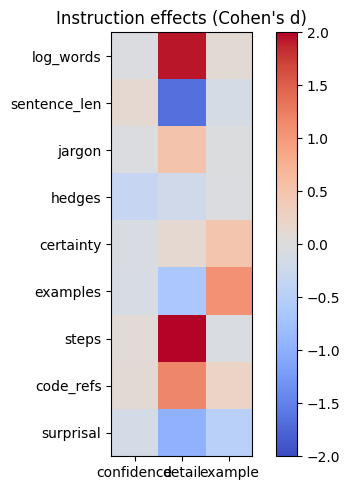

In [8]:
# Manipulation check: did each instruction move the features it should move?
check = []
for factor, levels in [("detail", ("brief", "detailed")), ("example", ("no_example", "example")), ("confidence", ("hedged", "assertive"))]:
    for f in FEATURES:
        a, b = expl.loc[expl[factor] == levels[0], f], expl.loc[expl[factor] == levels[1], f]
        pooled = np.sqrt((a.var() + b.var()) / 2)
        check.append({"factor": factor, "feature": f, levels[0]: a.mean(), levels[1]: b.mean(), "cohens_d": (b.mean() - a.mean()) / pooled if pooled > 0 else 0.0})
check = pd.DataFrame(check)
check.to_csv(os.path.join(OUT_DIR, "manipulation_check.csv"), index=False)
# Effect-size matrix
dmat = check.pivot(index="feature", columns="factor", values="cohens_d").loc[FEATURES]
print(dmat.round(2).to_string())
fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(dmat.values, cmap="coolwarm", vmin=-2, vmax=2)
ax.set_xticks(range(dmat.shape[1])); ax.set_xticklabels(dmat.columns); ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
ax.set_title("Instruction effects (Cohen's d)"); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig1_manipulation_check.png"), dpi=150); plt.show()

In [9]:
# Ground-truth developer types used only to simulate preferences (weights on standardised features)
TYPE_WEIGHTS = {
    # Novices like longer, example-rich, step-by-step, low-jargon, easy-to-read text
    "novice": {"log_words": 0.8, "sentence_len": -0.6, "jargon": -1.2, "examples": 1.2, "steps": 0.8, "surprisal": -0.8, "certainty": 0.3},
    # Experienced developers like short, technical text that points at the code
    "expert": {"log_words": -1.0, "jargon": 0.8, "hedges": -0.5, "examples": -0.3, "steps": -0.4, "code_refs": 1.0},
    # Verifiers distrust over-confident text and want claims tied to the code
    "verifier": {"certainty": -1.2, "hedges": 0.4, "code_refs": 0.8, "examples": 0.5},
}
TYPES = list(TYPE_WEIGHTS)
W_TRUE = np.array([[TYPE_WEIGHTS[t].get(f, 0.0) for f in FEATURES] for t in TYPES])
# Preference sharpness
BETA = 2.0
sim = np.random.default_rng(SEED)
# Row indices of explanations per snippet
by_snip = {s: np.where(expl["snippet"].values == s)[0] for s in SNIPPETS}
snip_names = list(SNIPPETS)
# Simulate users and their pairwise choices (Bradley-Terry)
def simulate_users(n, start_id):
    users, comps = [], []
    for u in range(start_id, start_id + n):
        t = int(sim.integers(len(TYPES)))
        w = W_TRUE[t] + sim.normal(0, 0.25, len(FEATURES))
        users.append({"user": u, "type": TYPES[t], "w": w})
        for c in range(N_COMPARISONS):
            s = snip_names[int(sim.integers(len(snip_names)))]
            a, b = sim.choice(by_snip[s], size=2, replace=False)
            p = 1 / (1 + np.exp(-BETA * (X[a] - X[b]) @ w))
            comps.append({"user": u, "order": c, "a": int(a), "b": int(b), "y": int(sim.random() < p)})
    return pd.DataFrame(users), pd.DataFrame(comps)
train_users, train_comps = simulate_users(N_TRAIN_USERS, 0)
test_users, test_comps = simulate_users(N_TEST_USERS, 10000)
# Feature differences of every comparison
def diffs(comps):
    return X[comps["a"].values] - X[comps["b"].values]
print(train_users["type"].value_counts().to_string())
print("Training comparisons:", len(train_comps), "| test comparisons:", len(test_comps))

type
expert      46
novice      42
verifier    32
Training comparisons: 4800 | test comparisons: 2400


In [10]:
# Mixture of sparse Bradley-Terry experts with user-level routing, trained by EM
def log_sigmoid(z):
    return -np.logaddexp(0, -z)
# Per-user log-likelihood of every expert
def user_loglik(D, y, users, W):
    z = D @ W.T
    ll = np.where(y[:, None] == 1, log_sigmoid(z), log_sigmoid(-z))
    return pd.DataFrame(ll).groupby(users).sum()
# EM fit
def fit_moe(comps, n_experts, seed=SEED, iters=EM_ITERS):
    r_ng = np.random.default_rng(seed)
    D, y, users = diffs(comps), comps["y"].values, comps["user"].values
    uniq = np.unique(users)
    # Random soft assignment of users to experts
    R = pd.DataFrame(r_ng.dirichlet(np.ones(n_experts), size=len(uniq)), index=uniq)
    W = np.zeros((n_experts, D.shape[1]))
    pi = np.ones(n_experts) / n_experts
    for _ in range(iters):
        # M-step: one sparse logistic expert per component, weighted by responsibilities
        for k in range(n_experts):
            sw = R.loc[users, k].values + 1e-6
            clf = LogisticRegression(penalty="l1", C=L1_C, solver="liblinear", fit_intercept=False)
            clf.fit(D, y, sample_weight=sw)
            W[k] = clf.coef_[0]
        pi = R.mean(axis=0).values
        # E-step: posterior over experts for each user
        L = user_loglik(D, y, users, W) + np.log(pi + 1e-12)
        L = L.sub(L.max(axis=1), axis=0)
        R = np.exp(L); R = R.div(R.sum(axis=1), axis=0)
    total_ll = float((user_loglik(D, y, users, W) + np.log(pi + 1e-12)).apply(lambda r: np.logaddexp.reduce(r.values), axis=1).sum())
    return {"W": W, "pi": pi, "R": R, "ll": total_ll}
# Posterior over experts for a new user from a few comparisons
def route(model, comps_few):
    lp = np.log(model["pi"] + 1e-12).copy()
    if len(comps_few):
        z = diffs(comps_few) @ model["W"].T
        y = comps_few["y"].values[:, None]
        lp = lp + np.where(y == 1, log_sigmoid(z), log_sigmoid(-z)).sum(axis=0)
    p = np.exp(lp - lp.max())
    return p / p.sum()
# Probability that A is preferred, averaged over experts
def moe_prob(model, r, D):
    return (1 / (1 + np.exp(-(D @ model["W"].T)))) @ r
print("MoE functions ready.")

MoE functions ready.


In [11]:
# Choose the number of experts on held-out comparisons of validation users
val_ids = set(train_users["user"].sample(frac=0.25, random_state=SEED))
fit_part = train_comps[~train_comps["user"].isin(val_ids)]
val_part = train_comps[train_comps["user"].isin(val_ids)]
sel = []
for k in N_EXPERTS_GRID:
    m = fit_moe(fit_part, k)
    # Route each validation user with its first half, score the second half
    ll = 0.0
    for u, g in val_part.groupby("user"):
        g = g.sort_values("order"); half = len(g) // 2
        r = route(m, g.iloc[:half])
        p = np.clip(moe_prob(m, r, diffs(g.iloc[half:])), 1e-9, 1 - 1e-9)
        yy = g.iloc[half:]["y"].values
        ll += float(np.sum(yy * np.log(p) + (1 - yy) * np.log(1 - p)))
    sel.append({"n_experts": k, "heldout_loglik": ll})
    print(f"{k} experts: held-out log-likelihood {ll:.1f}")
sel = pd.DataFrame(sel)
sel.to_csv(os.path.join(OUT_DIR, "expert_number_selection.csv"), index=False)
N_EXPERTS = int(sel.loc[sel["heldout_loglik"].idxmax(), "n_experts"])
# Final model on all training users
MOE = fit_moe(train_comps, N_EXPERTS)
print("Chosen number of experts:", N_EXPERTS, "| mixture weights:", np.round(MOE["pi"], 3))

1 experts: held-out log-likelihood -377.1
2 experts: held-out log-likelihood -291.9
3 experts: held-out log-likelihood -265.4
4 experts: held-out log-likelihood -254.0
5 experts: held-out log-likelihood -266.4
Chosen number of experts: 4 | mixture weights: [0.267 0.366 0.017 0.35 ]


Adjusted Rand index (users -> experts vs true types): 0.952
 expert matched_type  cosine
      0     verifier   0.992
      1       expert   0.996
      3       novice   0.985

Expert weights (zeros come from the L1 penalty):
          log_words  sentence_len  jargon  hedges  certainty  examples  steps  code_refs  surprisal
expert_0      -0.00          0.18    0.00    0.49      -1.40      0.61  -0.14       0.99       0.06
expert_1      -1.55         -0.18    1.14   -0.71       0.00     -0.51  -0.65       1.38      -0.04
expert_2      -0.30         -0.05    0.00   -0.47      -0.17      0.00   0.29       1.23      -0.15
expert_3       0.86         -0.91   -1.89    0.07       0.55      1.69   0.98       0.37      -1.32


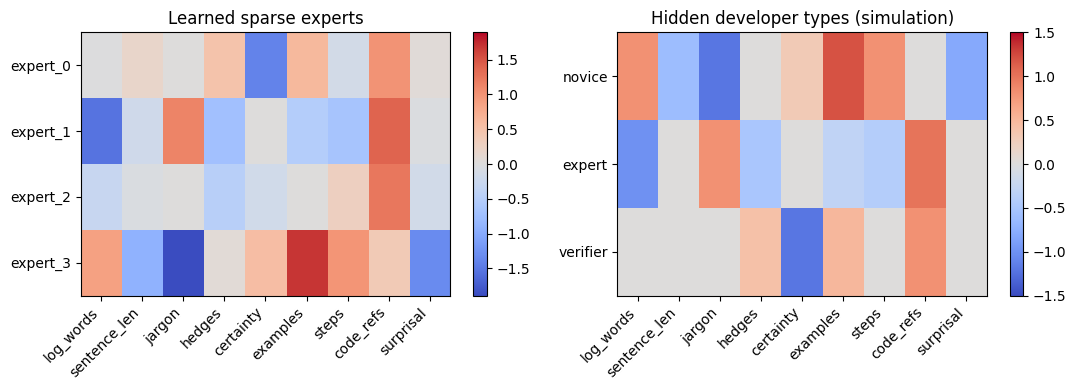

In [12]:
# Did the experts recover the hidden developer types?
assign = MOE["R"].idxmax(axis=1)
true_type = train_users.set_index("user")["type"].loc[assign.index]
ari = adjusted_rand_score(true_type, assign)
# Cosine similarity between learned experts and true type weights, matched one-to-one
def cos(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))
C = np.array([[cos(MOE["W"][k], W_TRUE[t]) for t in range(len(TYPES))] for k in range(N_EXPERTS)])
rk, ct = linear_sum_assignment(-C)
match = pd.DataFrame({"expert": rk, "matched_type": [TYPES[t] for t in ct], "cosine": C[rk, ct]})
print("Adjusted Rand index (users -> experts vs true types):", round(ari, 3))
print(match.round(3).to_string(index=False))
# Sparse expert weights table
wtab = pd.DataFrame(MOE["W"], columns=FEATURES, index=[f"expert_{k}" for k in range(N_EXPERTS)])
wtab.to_csv(os.path.join(OUT_DIR, "expert_weights.csv"))
print("\nExpert weights (zeros come from the L1 penalty):")
print(wtab.round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(wtab.values, cmap="coolwarm", vmin=-np.abs(wtab.values).max() - 1e-9, vmax=np.abs(wtab.values).max() + 1e-9, aspect="auto")
axes[0].set_xticks(range(len(FEATURES))); axes[0].set_xticklabels(FEATURES, rotation=45, ha="right"); axes[0].set_yticks(range(N_EXPERTS)); axes[0].set_yticklabels(wtab.index)
axes[0].set_title("Learned sparse experts"); plt.colorbar(im, ax=axes[0])
im2 = axes[1].imshow(W_TRUE, cmap="coolwarm", vmin=-1.5, vmax=1.5, aspect="auto")
axes[1].set_xticks(range(len(FEATURES))); axes[1].set_xticklabels(FEATURES, rotation=45, ha="right"); axes[1].set_yticks(range(len(TYPES))); axes[1].set_yticklabels(TYPES)
axes[1].set_title("Hidden developer types (simulation)"); plt.colorbar(im2, ax=axes[1])
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig2_experts.png"), dpi=150); plt.show()

                       method  K  accuracy  ci_low  ci_high
mixture of experts (few-shot)  1     0.682   0.644    0.725
mixture of experts (few-shot)  2     0.693   0.651    0.734
mixture of experts (few-shot)  4     0.716   0.671    0.756
mixture of experts (few-shot)  8     0.768   0.734    0.800
mixture of experts (few-shot) 16     0.772   0.737    0.803
             one global model  1     0.620   0.584    0.654
             one global model  2     0.620   0.584    0.654
             one global model  4     0.620   0.584    0.654
             one global model  8     0.620   0.584    0.654
             one global model 16     0.620   0.584    0.654
        oracle (true weights)  1     0.835   0.812    0.860
        oracle (true weights)  2     0.835   0.812    0.860
        oracle (true weights)  4     0.835   0.812    0.860
        oracle (true weights)  8     0.835   0.812    0.860
        oracle (true weights) 16     0.835   0.812    0.860
    per-user model (few-shot)  1     0.5

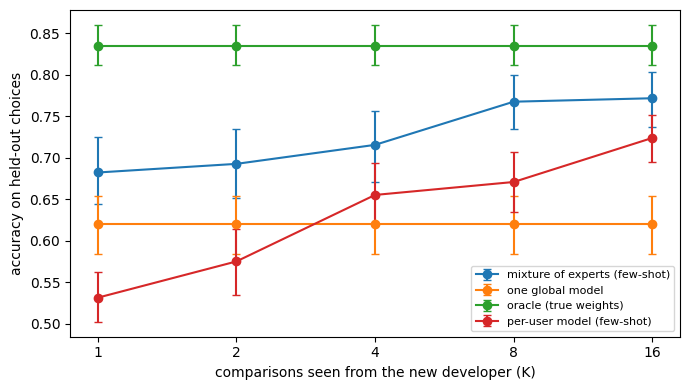

In [13]:
# Few-shot adaptation to new developers: predict their remaining choices from K comparisons
glob = LogisticRegression(max_iter=2000, fit_intercept=False).fit(diffs(train_comps), train_comps["y"].values)
def boot_ci(v, n_boot=N_BOOT, seed=SEED):
    v = np.asarray(v, dtype=float); r = np.random.default_rng(seed)
    m = [r.choice(v, size=len(v), replace=True).mean() for _ in range(n_boot)]
    return float(v.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))
acc_rows = []
for _, uinfo in test_users.iterrows():
    g = test_comps[test_comps["user"] == uinfo["user"]].sort_values("order")
    ev = g.iloc[-N_EVAL_COMPARISONS:]; pool = g.iloc[:-N_EVAL_COMPARISONS]
    Dev, yev = diffs(ev), ev["y"].values
    # Accuracy of the true preference weights (upper bound given choice noise)
    oracle = float(((Dev @ uinfo["w"] > 0).astype(int) == yev).mean())
    for k in K_SHOTS:
        few = pool.iloc[:k]
        # Mixture of experts routed with K comparisons
        p_moe = moe_prob(MOE, route(MOE, few), Dev)
        # Per-user logistic regression from K comparisons only (needs both answers present)
        if few["y"].nunique() == 2:
            own = LogisticRegression(max_iter=2000, fit_intercept=False).fit(diffs(few), few["y"].values)
            p_own = own.predict_proba(Dev)[:, 1]
        else:
            p_own = np.full(len(ev), float(few["y"].mean()))
        p_glob = glob.predict_proba(Dev)[:, 1]
        for name, p in [("mixture of experts (few-shot)", p_moe), ("per-user model (few-shot)", p_own), ("one global model", p_glob)]:
            acc_rows.append({"user": uinfo["user"], "type": uinfo["type"], "K": k, "method": name, "accuracy": float(((p > 0.5).astype(int) == yev).mean())})
        acc_rows.append({"user": uinfo["user"], "type": uinfo["type"], "K": k, "method": "oracle (true weights)", "accuracy": oracle})
acc = pd.DataFrame(acc_rows)
acc_summary = pd.DataFrame([dict(method=m, K=k, **dict(zip(["accuracy", "ci_low", "ci_high"], boot_ci(t["accuracy"])))) for (m, k), t in acc.groupby(["method", "K"])])
acc_summary.to_csv(os.path.join(OUT_DIR, "fewshot_adaptation.csv"), index=False)
print(acc_summary.round(3).to_string(index=False))
print("\nAccuracy by developer type at K = 4:")
print(acc[acc["K"] == 4].groupby(["type", "method"])["accuracy"].mean().unstack().round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 4))
for m, t in acc_summary.groupby("method"):
    ax.errorbar(t["K"], t["accuracy"], yerr=[t["accuracy"] - t["ci_low"], t["ci_high"] - t["accuracy"]], marker="o", capsize=3, label=m)
ax.set_xscale("log", base=2); ax.set_xticks(K_SHOTS); ax.set_xticklabels(K_SHOTS)
ax.set_xlabel("comparisons seen from the new developer (K)"); ax.set_ylabel("accuracy on held-out choices"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig3_fewshot_adaptation.png"), dpi=150); plt.show()

Change in predicted preference after removing the top-m features (higher = more faithful):
               method  top_m  comprehensiveness  ci_low  ci_high
contribution contrast      1             0.2552  0.2421   0.2674
contribution contrast      2             0.2177  0.2051   0.2319
contribution contrast      3             0.2271  0.2166   0.2393
               random      1             0.0555  0.0483   0.0620
               random      2             0.0901  0.0816   0.0985
               random      3             0.1234  0.1136   0.1326
 routing weights only      1             0.1443  0.1329   0.1556
 routing weights only      2             0.1891  0.1766   0.2031
 routing weights only      3             0.1949  0.1828   0.2084


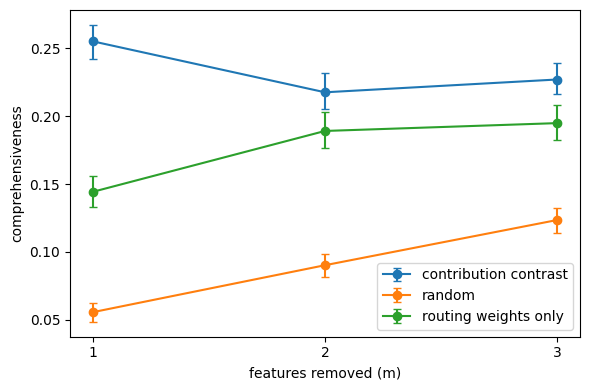

In [14]:
# Faithfulness: do explanations of the reward model point at the features that really drive its decision?
K_FAITH = 8
TOPS = [1, 2, 3]
f_rows = []
fr = np.random.default_rng(SEED)
for _, uinfo in test_users.iterrows():
    g = test_comps[test_comps["user"] == uinfo["user"]].sort_values("order")
    r = route(MOE, g.iloc[:K_FAITH])
    top_expert = int(np.argmax(r))
    ev = g.iloc[-N_EVAL_COMPARISONS:]
    for a_i, b_i in zip(ev["a"].astype(int), ev["b"].astype(int)):
        d = X[a_i] - X[b_i]
        p0 = float(moe_prob(MOE, r, d[None])[0])
        # Response-level contribution contrast: each feature's share of this specific decision
        contrib = np.abs((r @ MOE["W"]) * d)
        # Routing-only explanation: what the top expert cares about in general, ignoring this pair
        routing = np.abs(MOE["W"][top_expert])
        # Random ranking as a control
        rand = fr.random(len(FEATURES))
        for name, score in [("contribution contrast", contrib), ("routing weights only", routing), ("random", rand)]:
            order = np.argsort(-score)
            for m in TOPS:
                d2 = d.copy(); d2[order[:m]] = 0.0
                p1 = float(moe_prob(MOE, r, d2[None])[0])
                f_rows.append({"method": name, "top_m": m, "comprehensiveness": abs(p0 - p1)})
faith = pd.DataFrame(f_rows)
faith_summary = pd.DataFrame([dict(method=mth, top_m=m, **dict(zip(["comprehensiveness", "ci_low", "ci_high"], boot_ci(t["comprehensiveness"])))) for (mth, m), t in faith.groupby(["method", "top_m"])])
faith_summary.to_csv(os.path.join(OUT_DIR, "faithfulness.csv"), index=False)
print("Change in predicted preference after removing the top-m features (higher = more faithful):")
print(faith_summary.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 4))
for mth, t in faith_summary.groupby("method"):
    ax.errorbar(t["top_m"], t["comprehensiveness"], yerr=[t["comprehensiveness"] - t["ci_low"], t["ci_high"] - t["comprehensiveness"]], marker="o", capsize=3, label=mth)
ax.set_xlabel("features removed (m)"); ax.set_ylabel("comprehensiveness"); ax.set_xticks(TOPS); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig4_faithfulness.png"), dpi=150); plt.show()

In [15]:
# Personalised choice of explanation: pick the variant the routed reward model likes best for each snippet
K_SELECT = 8
glob_w = glob.coef_[0]
sel_rows = []
for _, uinfo in test_users.iterrows():
    g = test_comps[test_comps["user"] == uinfo["user"]].sort_values("order")
    r = route(MOE, g.iloc[:K_SELECT])
    w_pers = r @ MOE["W"]
    for s, ix in by_snip.items():
        true_u = X[ix] @ uinfo["w"]
        best = true_u.max()
        # Regret = how much worse the chosen explanation is than the best one for this person
        sel_rows.append({"user": uinfo["user"], "type": uinfo["type"], "snippet": s,
                         "regret_personalised": best - true_u[int(np.argmax(X[ix] @ w_pers))],
                         "regret_global": best - true_u[int(np.argmax(X[ix] @ glob_w))],
                         "regret_random": best - true_u.mean()})
sel_df = pd.DataFrame(sel_rows)
sel_df.to_csv(os.path.join(OUT_DIR, "personalised_selection.csv"), index=False)
sel_summary = pd.DataFrame([dict(policy=c.replace("regret_", ""), **dict(zip(["regret", "ci_low", "ci_high"], boot_ci(sel_df[c])))) for c in ["regret_personalised", "regret_global", "regret_random"]])
print(sel_summary.round(3).to_string(index=False))
print("\nRegret by developer type:")
print(sel_df.groupby("type")[["regret_personalised", "regret_global", "regret_random"]].mean().round(3).to_string())
# Example: which variant each type gets for one snippet
demo_s = "binary_search"
for t in TYPES:
    u = test_users[test_users["type"] == t]
    if len(u):
        uid = u.iloc[0]["user"]
        g = test_comps[test_comps["user"] == uid].sort_values("order")
        w_pers = route(MOE, g.iloc[:K_SELECT]) @ MOE["W"]
        pick = by_snip[demo_s][int(np.argmax(X[by_snip[demo_s]] @ w_pers))]
        print(f"\n[{t}] gets variant {tuple(expl.loc[pick, ['detail', 'example', 'confidence']])}:\n{expl.loc[pick, 'explanation'][:300]}")

      policy  regret  ci_low  ci_high
personalised   0.293   0.263    0.323
      global   1.069   0.997    1.140
      random   1.766   1.713    1.819

Regret by developer type:
          regret_personalised  regret_global  regret_random
type                                                       
expert                  0.297          0.751          1.290
novice                  0.133          1.432          2.559
verifier                0.415          1.160          1.703

[novice] gets variant ('detailed', 'example', 'assertive'):
This Python function performs a binary search on a sorted array to find the index of a given target value. Here's a detailed explanation of how it works:

1. **Initialization**:
   - `lo` is initialized to 0, which represents the start of the search range.
   - `hi` is initialized to `len(arr) - 1`,

[expert] gets variant ('detailed', 'example', 'assertive'):
This Python function performs a binary search on a sorted array to find the index of a given targe

In [16]:
# Optional real data: pairwise_choices.csv with columns user, a, b, y (a and b are row numbers in explanations.csv, y = 1 if a was preferred)
REAL_PATH = os.path.join(WORK_DIR, "pairwise_choices.csv")
if os.path.exists(REAL_PATH):
    real = pd.read_csv(REAL_PATH)
    real = real[real["a"].between(0, len(X) - 1) & real["b"].between(0, len(X) - 1) & real["y"].isin([0, 1])]
    real["order"] = real.groupby("user").cumcount()
    real_moe = fit_moe(real, N_EXPERTS)
    out = pd.DataFrame(real_moe["R"].values, index=real_moe["R"].index, columns=[f"expert_{k}" for k in range(N_EXPERTS)])
    out.to_csv(os.path.join(OUT_DIR, "real_user_routing.csv"))
    print(pd.DataFrame(real_moe["W"], columns=FEATURES).round(2).to_string())
else:
    print("No real preference file found; results above use simulated developers.")

No real preference file found; results above use simulated developers.


In [17]:
# Headline numbers for the proposal
summary = {
    "n_explanations": len(expl),
    "manipulation_check_cohens_d": dmat.round(3).to_dict(),
    "n_experts_selected": N_EXPERTS,
    "type_recovery_ARI": round(float(ari), 4),
    "expert_type_cosine": match.round(4).to_dict(orient="records"),
    "fewshot_adaptation": acc_summary.round(4).to_dict(orient="records"),
    "faithfulness": faith_summary.round(4).to_dict(orient="records"),
    "personalised_selection_regret": sel_summary.round(4).to_dict(orient="records"),
}
with open(os.path.join(OUT_DIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=str)
print("Saved files:")
for f in sorted(os.listdir(OUT_DIR)):
    print(" -", f)

Saved files:
 - expert_number_selection.csv
 - expert_weights.csv
 - explanations.csv
 - explanations_with_features.csv
 - faithfulness.csv
 - fewshot_adaptation.csv
 - fig1_manipulation_check.png
 - fig2_experts.png
 - fig3_fewshot_adaptation.png
 - fig4_faithfulness.png
 - manipulation_check.csv
 - personalised_selection.csv
 - summary.json
